**Цель работы**: Научиться представлять зависимости между случайными величинами с помощью байесовской сети, самостоятельно строить структуру графа и выполнять вероятностный вывод при наличии дополнительной информации

# Выбор данных

- Самостоятельно выбрать открытый датасет, содержащий несколько признаков, между которыми можно содержательно предположить зависимости
- Кратко описать:
    - что представляет собой один объект
    - какие переменные присутствуют
    - что они означают
    - какие зависимости между ними могут существовать

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx # построение графа
import seaborn as sns


raw = pd.read_csv("data/penguins.csv")
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"] # список непрерывных признаков

print("Размер данных:", raw.shape)
display(raw.isna().sum().to_frame("пропусков").T)
display(raw.groupby(["species", "sex"])[num_cols].mean().round(0)) # средние по каждой паре для числовых признаков

r_all = raw["bill_length_mm"].corr(raw["bill_depth_mm"]) # корреляция Пирсона по всей выборке
r_in = raw.groupby("species")[["bill_length_mm", "bill_depth_mm"]].apply(lambda g: g["bill_length_mm"].corr(g["bill_depth_mm"])) 
# корреляция внутри каждого вида; apply применяет лямбду к каждой группе-виду

print(f"Корреляция длины и глубины клюва: по всей выборке {r_all:.2f}, внутри видов:", r_in.round(2).to_dict())

Размер данных: (344, 9)


,id,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
пропусков,0,0,0,2,2,2,2,11,0


bill_length_mm  bill_depth_mm  flipper_length_mm  \
species   sex                                                        
Adelie    female            37.0           18.0              188.0   
          male              40.0           19.0              192.0   
Chinstrap female            47.0           18.0              192.0   
          male              51.0           19.0              200.0   
Gentoo    female            46.0           14.0              213.0   
          male              49.0           16.0              222.0   

                  body_mass_g  
species   sex                  
Adelie    female       3369.0  
          male         4043.0  
Chinstrap female       3527.0  
          male         3939.0  
Gentoo    female       4680.0  
          male         5485.0

Корреляция длины и глубины клюва: по всей выборке -0.24, внутри видов: {'Adelie': 0.39, 'Chinstrap': 0.65, 'Gentoo': 0.64}


Вид × Остров (число наблюдений):


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


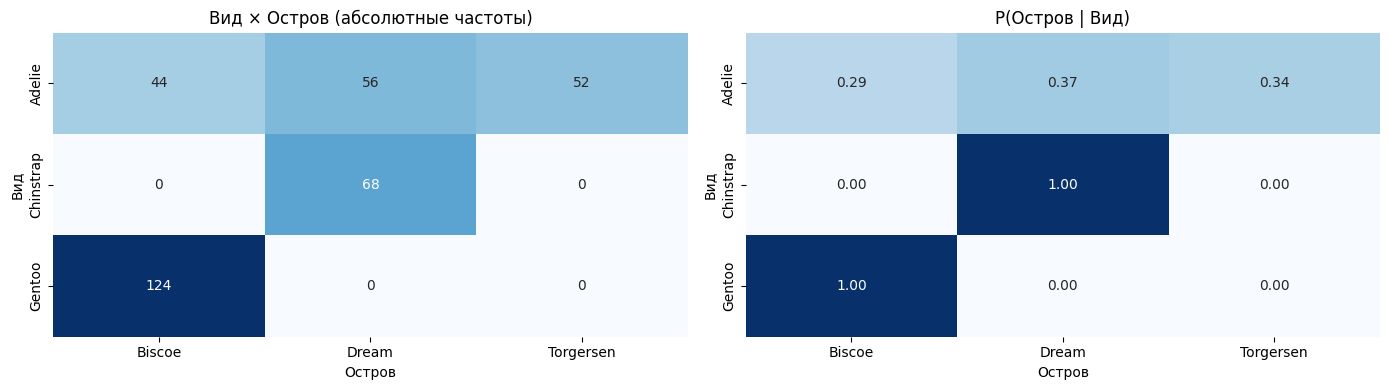

Корреляции (вся выборка):


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,-0.24,0.66,0.60
bill_depth_mm,-0.24,1.00,-0.58,-0.47
flipper_length_mm,0.66,-0.58,1.00,0.87
body_mass_g,0.60,-0.47,0.87,1.00


Корреляции (среднее внутри видов):


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,0.56,0.49,0.58
bill_depth_mm,0.56,1.00,0.53,0.63
flipper_length_mm,0.49,0.53,1.00,0.60
body_mass_g,0.58,0.63,0.60,1.00


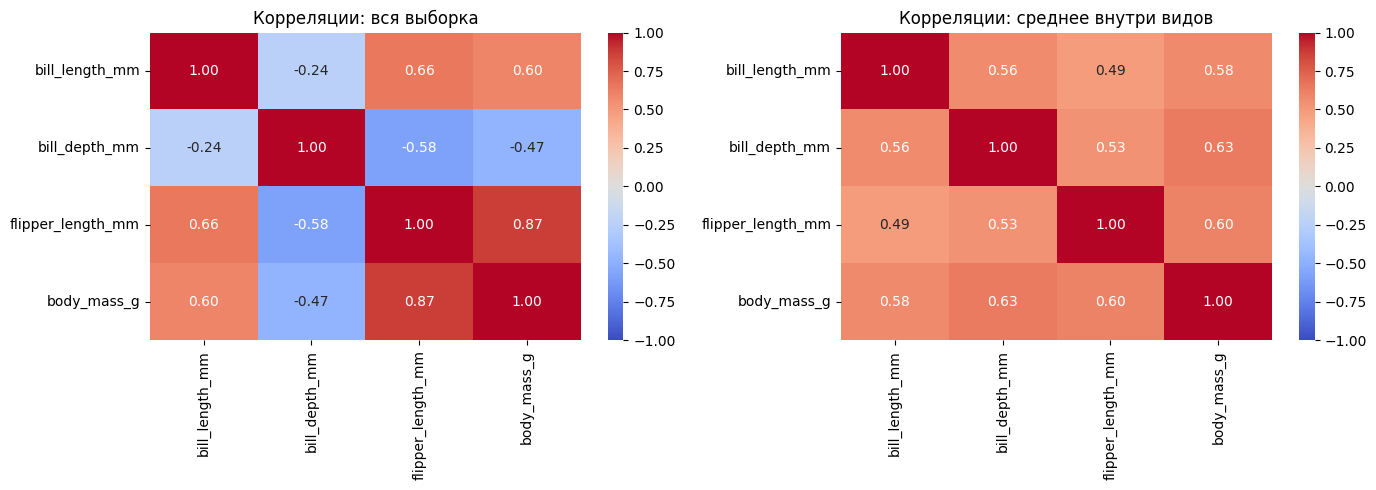

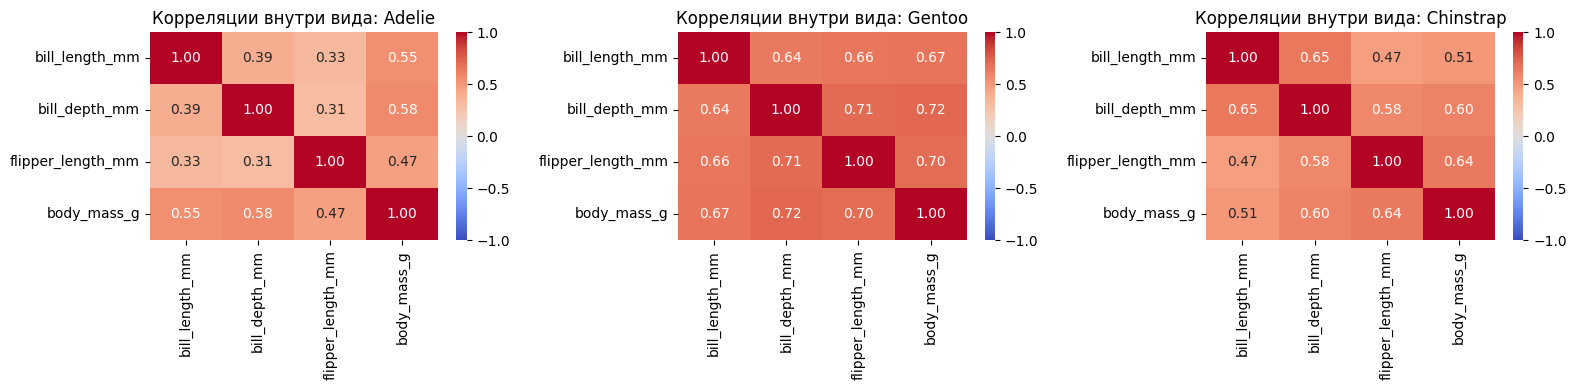

Средние по (вид, пол):


bill_length_mm  bill_depth_mm  flipper_length_mm  \
species   sex                                                        
Adelie    female            37.3           17.6              187.8   
          male              40.4           19.1              192.4   
Chinstrap female            46.6           17.6              191.7   
          male              51.1           19.3              199.9   
Gentoo    female            45.6           14.2              212.7   
          male              49.5           15.7              221.5   

                  body_mass_g  
species   sex                  
Adelie    female       3368.8  
          male         4043.5  
Chinstrap female       3527.2  
          male         3939.0  
Gentoo    female       4679.7  
          male         5484.8

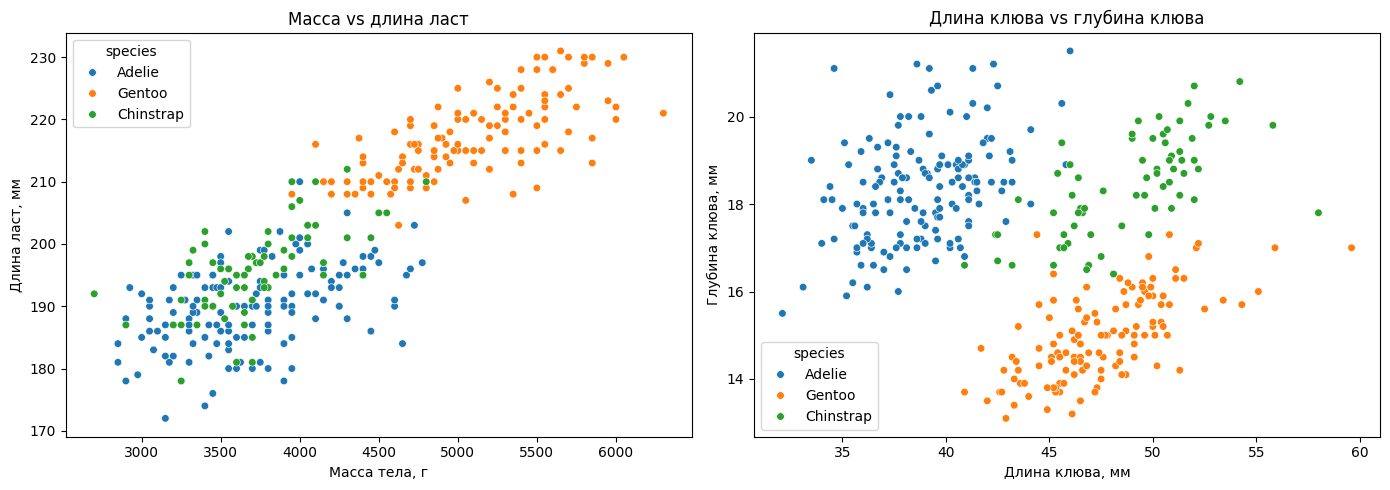

In [2]:
# Наглядное обоснование предполагаемых зависимостей

# Таблица сопряжённости (кто где живёт)
ct = pd.crosstab(raw["species"], raw["island"]) # считаем кол-во объектов каждой пары
print("Вид × Остров (число наблюдений):")
display(ct)

# Heatmap
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0])  # annot — подписать числа в ячейках; fmt — целые числа; cbar — наличие цветовой шкалы справа
ax[0].set_title("Вид × Остров (абсолютные частоты)")
ax[0].set_xlabel("Остров")
ax[0].set_ylabel("Вид")


ct_norm = ct.div(ct.sum(axis=1), axis=0)  # нормировка по строкам: P(Island | Species)
sns.heatmap(ct_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax[1])
ax[1].set_title("P(Остров | Вид)")
ax[1].set_xlabel("Остров")
ax[1].set_ylabel("Вид")
plt.tight_layout()
plt.show()

# Матрица корреляций Пирсона для числовых признаков
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
corr_all = raw[num_cols].corr()

corr_within = (
    raw.groupby("species")[num_cols]
    .apply(lambda g: g.corr())
    .groupby(level=1)
    .mean()
    .loc[num_cols, num_cols]
)  # corr_within — средняя внутривидовая корреляция; это сравнение демонстрирует наличие парадокса Пирсона

print("Корреляции (вся выборка):")
display(corr_all.round(2))
print("Корреляции (среднее внутри видов):")
display(corr_within.round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(corr_all, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Корреляции: вся выборка")
sns.heatmap(
    corr_within, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1]
)
ax[1].set_title("Корреляции: среднее внутри видов")
plt.tight_layout()
plt.show()

# Матрица корреляций внутри видов
fig2, axes = plt.subplots(1, 3, figsize=(16, 4))
for a, sp in zip(axes, raw["species"].unique()):
    sub = raw.loc[raw["species"] == sp, num_cols]
    sns.heatmap(
        sub.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=a
    )
    a.set_title(f"Корреляции внутри вида: {sp}")
plt.tight_layout()
plt.show()

# Средние по (вид, пол)
means = raw.groupby(["species", "sex"])[num_cols].mean().round(1)
print("Средние по (вид, пол):")
display(means)

# Scatter-графики пар признаков: масса vs ласты; длина клюва vs глубина — парадокс Симпсона
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=raw, x="body_mass_g", y="flipper_length_mm", hue="species", s=30, ax=ax[0])  # hue — цвет по виду; s — размер точек
ax[0].set_title("Масса vs длина ласт")
ax[0].set_xlabel("Масса тела, г")
ax[0].set_ylabel("Длина ласт, мм")

sns.scatterplot(data=raw, x="bill_length_mm", y="bill_depth_mm", hue="species", s=30, ax=ax[1])
ax[1].set_title("Длина клюва vs глубина клюва")
ax[1].set_xlabel("Длина клюва, мм")
ax[1].set_ylabel("Глубина клюва, мм")
plt.tight_layout()
plt.show()


**Датасет:** Palmer Penguins -  измерения пингвинов архипелага Палмер (Антарктика).

**Один объект** -  пингвин, у которого записаны вид, остров обитания, пол и 4 размерности тела.

**Переменные.**

| Переменная | Тип | Что означает |
|---|---|---|
| `Species` | категориальная (Adelie, Chinstrap, Gentoo) | вид пингвина |
| `Island` | категориальная (Biscoe, Dream, Torgersen) | остров, на котором наблюдали пингвина |
| `Sex` | категориальная (Female, Male) | пол |
| `BodyMass` | непрерывная (г) | масса тела |
| `FlipperLength` | непрерывная (мм) | длина ласты |
| `BillLength` | непрерывная (мм) | длина клюва |
| `BillDepth` | непрерывная (мм) | глубина (высота) клюва |

**Какие зависимости можно предположить.**
- Вид определяет размеры тела (Gentoo заметно крупнее и тяжелее Adelie и Chinstrap) и форму клюва (у Gentoo клюв длиннее, но менее глубокий), а также то, на каких островах вид гнездится: Gentoo наблюдали только на Biscoe, Chinstrap только на Dream, Adelie на всех трёх.
- Пол влияет на размеры: самцы тяжелее и имеют более крупный клюв (половой диморфизм), внутри каждого вида.
- Масса тела и длина ласт растут вместе: более крупная птица имеет более длинные ласты.
- Остров сам по себе вряд ли влияет на размеры: его связь с размерами должна идти через вид.

**Интересный эффект в данных.** Корреляция длины и глубины клюва по всей выборке отрицательна, а внутри каждого вида положительна (парадокс Симпсона): общая отрицательная связь возникает только из-за различий между видами. Поэтому добавлять ребро между `BillLength` и `BillDepth` «по корреляции» было бы ошибкой.

# Подготовка данных

- Исследовать данные и подготовить их для построения байесовской сети
- Если непрерывные признаки необходимо преобразовать в категории, самостоятельно определить способ дискретизации и обосновать его
- Обратить внимание на:
    - пропущенные значения
    - редкие категории
    - количество возможных состояний переменных
    - достаточность количества наблюдений

In [3]:
df = raw.dropna().rename(columns={"species": "Species", "island": "Island", "sex": "Sex", "body_mass_g": "BodyMass",
                                  "flipper_length_mm": "FlipperLength", "bill_length_mm": "BillLength",
                                  "bill_depth_mm": "BillDepth"}).reset_index(drop=True)  # dropna() — удаляем строки с пропусками; rename — единые имена для вершин графа; reset_index(drop=True) — чтобы индексы строк снова шли подряд, без пропусков

edges = {}  # границы интервалов для печати
for c in ["BodyMass", "FlipperLength", "BillLength", "BillDepth"]:  
    df[c], edges[c] = pd.qcut(df[c], 3, labels=["low", "mid", "high"], retbins=True)  # qcut — равночастотная дискретизация на 3 интервала (терцили); retbins — возвращает границы интервалов
df = df.astype("category")

print("Удалено строк с пропусками:", len(raw) - len(df), "| осталось:", len(df))
print("Границы интервалов:", {c: e.round(1).tolist() for c, e in edges.items()})
print("Число состояний:", df.nunique().to_dict())
display(df[["Species", "Island", "Sex"]].apply(lambda s: s.value_counts()).fillna(0).astype(int).T)
display(df.groupby(["Species", "BodyMass"], observed=False).size().unstack())  # таблица сопряжённости Species × BodyMass; observed — показывать пустые комбинации, а не пропускать их

Удалено строк с пропусками: 11 | осталось: 333
Границы интервалов: {'BodyMass': [2700.0, 3700.0, 4550.0, 6300.0], 'FlipperLength': [172.0, 192.0, 209.0, 231.0], 'BillLength': [32.1, 40.9, 46.8, 59.6], 'BillDepth': [13.1, 16.2, 18.3, 21.5]}
Число состояний: {'id': 333, 'Species': 3, 'Island': 3, 'BillLength': 3, 'BillDepth': 3, 'FlipperLength': 3, 'BodyMass': 3, 'Sex': 2, 'year': 3}


,Adelie,Biscoe,Chinstrap,Dream,Gentoo,Torgersen,female,male
Species,146,0,68,0,119,0,0,0
Island,0,163,0,123,0,47,0,0
Sex,0,0,0,0,0,0,165,168


BodyMass,low,mid,high
Species,,,
Adelie,77,62,7
Chinstrap,36,31,1
Gentoo,0,17,102


**Пропущенные значения.** Пропуски есть у `Sex` (11 строк). Строки с пропусками удалены: это ≈ 3% данных. Пропуски в основном в `Sex`, который нужен как родительская вершина, заполнять пол по другим признакам значило бы подмешивать в сеть собственные предположения. Осталось 333 наблюдения.

**Дискретизация.** Байесовская сеть здесь дискретная, поэтому 4 непрерывных признака разбиты на **три интервала с равным числом объектов** (`low` / `mid` / `high`, терцили).
- Равночастотные интервалы гарантируют, что ни одно состояние не окажется редким; при равной ширине интервалов в хвостах оказались бы единицы пингвинов.
- Три состояния -  компромисс. При 333 наблюдениях таблицы условных вероятностей (CPT) должны оцениваться по достаточному числу объектов.
- Цена: часть информации теряется, а границы интервалов не совпадают с границами видов.

**Редкие категории и достаточность данных.** Все значения категориальных признаков встречаются не менее чем у нескольких десятков пингвинов (самый малочисленный вид -  Chinstrap, ≈ 20%; остров Torgersen -  ≈ 15%). Но некоторые родительские конфигурации пусты по смыслу задачи: например, нет Gentoo с низкой массой, поскольку Gentoo существенно тяжелее. Для таких конфигураций CPT оценивается только по априорному сглаживанию. Число состояний невелико (2–3 у каждой вершины), поэтому самые большие CPT содержат не более 3 × 3 × 3 = 27 значений.

# Постановка вопросов

- До построения сети сформулировать не менее 3 вопросов, на которые хотим получить ответ с помощью вероятностной модели. Вопросы должны иметь содержательный смысл для выбранного датасета

1. **Пол и масса.** Как изменится вероятность того, что пингвин тяжёлый (`BodyMass = high`), если известно, что это самец, и как она изменится, если дополнительно известно, что это Gentoo?
2. **Остров и вид.** Как знание острова меняет вероятности видов? В частности, можно ли встретить Gentoo на Dream или Torgersen и что можно сказать о виде на Biscoe?
3. **Пол по массе (эффект объяснения)**. Если пингвин тяжёлый, как меняется вероятность того, что это самец? Как изменится эта вероятность, если вдобавок известно, что это Gentoo?
4. **Вид по размерам.** Если известно, что у пингвина длинные ласты и неглубокий клюв, какова вероятность каждого вида?

Дополнительно в разделе «Эксперимент с evidence» исследуется, как меняется распределение массы при последовательном добавлении информации.

# Построение графа

- Самостоятельно предложить структуру байесовской сети. Граф должен быть ориентированным ациклическим графом (DAG)
- Не добавлять ребро только на основании высокой корреляции между признаками
- Визуализировать получившуюся сеть. Граф должен быть читаемым и не содержать лишних вершин и связей без объяснения

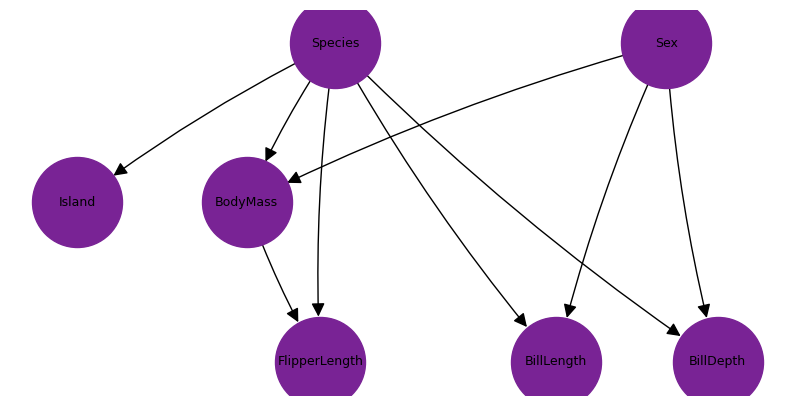

In [4]:
parents = {"Species": [], "Sex": [], "Island": ["Species"], "BodyMass": ["Species", "Sex"],
           "FlipperLength": ["Species", "BodyMass"], "BillLength": ["Species", "Sex"], "BillDepth": ["Species", "Sex"]}  
# словарь «вершина → список её родителей»

G = nx.DiGraph([(p, v) for v, ps in parents.items() for p in ps])  # генератор пар (родитель, потомок); nx.DiGraph — ориентированный граф
assert nx.is_directed_acyclic_graph(G)  # проверка: граф ациклический; если случайно образовался цикл, assert упадёт

pos = {"Species": (2, 2), "Sex": (6.5, 2), "Island": (-1.5, 1), "BodyMass": (0.8, 1), "FlipperLength": (1.8, 0),
       "BillLength": (5.0, 0), "BillDepth": (7.2, 0)}
fig, ax = plt.subplots(figsize=(10, 5))
nx.draw_networkx(G, pos, ax=ax, node_color="#792395", node_size=4200, font_size=9, arrowsize=20, connectionstyle="arc3,rad=0.05")
ax.axis("off")
plt.show()

В графе 7 вершин и 9 рёбер. Корневые вершины -  `Species` и `Sex` (их причины не входят в набор данных).

| Ребро | Почему есть зависимость | Почему такое направление |
|---|---|---|
| `Species → Island` | вид определяет, на каких островах он гнездится (Gentoo только на Biscoe, Chinstrap только на Dream) | вид задан биологически (генетикой) до того, как пингвина встретили на острове; остров -  место наблюдения колонии вида. Направление по данным не определимо, выбрано по смыслу |
| `Species → BodyMass` | виды заметно различаются по размеру (Gentoo тяжелее) | генетика вида определяет размер тела, а не наоборот |
| `Sex → BodyMass` | половой диморфизм: самцы тяжелее самок | пол определяется биологически, масса не может изменить пол |
| `Species → FlipperLength` | длина ласт -  видоспецифичный признак | генетика вида → морфология |
| `BodyMass → FlipperLength` | более крупная птица имеет более длинные ласты (внутри вида) | размер тела определяет размер конечностей |
| `Species → BillLength`, `Species → BillDepth` | форма клюва различается по видам (у Gentoo клюв длиннее и менее глубокий) | генетика вида → морфология |
| `Sex → BillLength`, `Sex → BillDepth` | у самцов клюв крупнее (диморфизм) | пол → морфология |

**Чего в графе нет намеренно.**
- `BillLength -  BillDepth`: общая отрицательная корреляция объясняется различиями видов (парадокс Симпсона), её причина представлена общими родителями `Species` и `Sex`.
- `Island → размеры`: связь острова с размерами идёт через вид, поэтому, если вид известен, остров ничего не добавляет.
- `Sex -  Species`, `Sex -  Island`: пол не зависит от вида и острова.
- Прямые связи между `FlipperLength` и клювом: их общая причина -  `Species` и `Sex`.

# Условные вероятности

- Оценить параметры сети по данным
- Исследовать таблицы условных вероятностей для нескольких наиболее интересных переменных
- Проверить, насколько полученные значения согласуются с исходными данными и ожиданиями

In [5]:
class BN:
    def __init__(self, df, parents, alpha=1.0):
        self.parents, self.nodes = parents, list(parents)
        self.states = {v: list(df[v].cat.categories) for v in self.nodes}  # для каждой вершины — список состояний; определяет, в каком порядке идут оси массива counts
        self.letters = {v: chr(97 + i) for i, v in enumerate(self.nodes)}  # каждой вершине — буква
        self.cpt, self.n = {}, {}  # cpt — таблица условных вероятностей вершины; n — число наблюдений в каждой конфигурации родителей

        for v, pa in parents.items():
            counts = np.zeros([len(self.states[c]) for c in pa + [v]])  # массив 0, размер «число состояний каждого родителя × потомка»
            np.add.at(counts, tuple(df[c].cat.codes.to_numpy() for c in pa + [v]), 1)  # np.add.at увеличивает счётчики по индексам
            self.n[v] = counts.sum(-1)  # сколько наблюдений в каждой конфигурации родителей
            counts += alpha  # лапласово сглаживание: +1 к каждой ячейке
            self.cpt[v] = counts / counts.sum(-1, keepdims=True)  # нормируем по последней оси
        self.joint = self._joint(self.parents, self.cpt)

    def _joint(self, parents, cpt):
        subs = ",".join("".join(self.letters[c] for c in parents[v] + [v]) for v in self.nodes)  # собираем строку подписей: для каждой вершины — буквы её родителей + её собственная
        return np.einsum(subs + "->" + "".join(self.letters[v] for v in self.nodes), *[cpt[v] for v in self.nodes])  
        # einsum перемножает CPT по общим индексам, суммирует по ним и выдаёт многомерный массив — совместное распределение

    def query(self, var, evidence=None, do=None):
        j = self.joint
        if do:
            pa = {**self.parents, **{k: [] for k in do}}  # вмешательство: переопределяем родителей для do-переменных — пустой список
            cp = {**self.cpt, **{k: np.eye(len(self.states[k]))[self.states[k].index(s)] for k, s in do.items()}}  # CPT do-переменной — это one-hot: P(do(X=s)=s)=1, все остальные 0
            j = self._joint(pa, cp)
        ev = evidence or {}
        idx = tuple(self.states[v].index(ev[v]) if v in ev else slice(None) for v in self.nodes)  # для каждой переменной: если она в evidence — берём числовой индекс состояния
        rest = [v for v in self.nodes if v not in ev]
        p = j[idx].sum(axis=tuple(i for i, v in enumerate(rest) if v != var))  # суммируем по всем осям, кроме var и получаем ненормированную P(var | evidence)
        return pd.Series(p / p.sum(), index=self.states[var], name=var) # нормируем

    def cpt_table(self, v):
        pa = self.parents[v]
        if not pa:
            return pd.DataFrame([self.cpt[v]], columns=self.states[v], index=["P"])  # у корневых вершин (Species, Sex) — строка вероятностей
        idx = pd.MultiIndex.from_product([self.states[p] for p in pa], names=pa)  # MultiIndex для строк таблицы: декартово произведение состояний родителей
        return pd.DataFrame(self.cpt[v].reshape(-1, len(self.states[v])), index=idx, columns=self.states[v]).assign(n=self.n[v].ravel().astype(int))
        # reshape - из многомерного CPT делаем таблицу; .assign добавляет последний столбец с числом наблюдений 

net = BN(df, parents)
for v in ["Island", "BodyMass", "FlipperLength"]:
    print(f"P({v} | {', '.join(parents[v])})")
    display(net.cpt_table(v).round(2))

P(Island | Species)


,Biscoe,Dream,Torgersen,n
Species,,,,
Adelie,0.30,0.38,0.32,146
Chinstrap,0.01,0.97,0.01,68
Gentoo,0.98,0.01,0.01,119


P(BodyMass | Species, Sex)


low   mid  high   n
Species   Sex                         
Adelie    female  0.87  0.12  0.01  73
          male    0.17  0.72  0.11  73
Chinstrap female  0.78  0.19  0.03  34
          male    0.24  0.70  0.05  34
Gentoo    female  0.02  0.30  0.69  58
          male    0.02  0.02  0.97  61

P(FlipperLength | Species, BodyMass)


low   mid  high    n
Species   BodyMass                       
Adelie    low       0.79  0.20  0.01   77
          mid       0.48  0.49  0.03   62
          high      0.40  0.50  0.10    7
Chinstrap low       0.54  0.44  0.03   36
          mid       0.03  0.85  0.12   31
          high      0.25  0.25  0.50    1
Gentoo    low       0.33  0.33  0.33    0
          mid       0.05  0.35  0.60   17
          high      0.01  0.09  0.90  102

In [6]:
gap = {v: (net.query(v) - df[v].value_counts(normalize=True).reindex(net.states[v])).abs().max() for v in net.nodes}  
# net.query(v) — маргинальное P(v) по сети; df[v].value_counts(normalize=True) — эмпирические частоты состояний

print("Максимальное расхождение маргинальных вероятностей сеть/данные:", {v: round(float(g), 3) for v, g in gap.items()})

sub = df[df["BillLength"] == "high"]
print("P(BillDepth=high | BillLength=high): данные =", round(float((sub["BillDepth"] == "high").mean()), 3),
      "| сеть =", round(float(net.query("BillDepth", {"BillLength": "high"})["high"]), 3))

Максимальное расхождение маргинальных вероятностей сеть/данные: {'Species': 0.001, 'Sex': 0.0, 'Island': 0.006, 'BodyMass': 0.003, 'FlipperLength': 0.002, 'BillLength': 0.003, 'BillDepth': 0.002}
P(BillDepth=high | BillLength=high): данные = 0.284 | сеть = 0.283


**Оценка параметров.** CPT оценены по частотам с лапласовым сглаживанием (добавлено по одному псевдонаблюдению на состояние): нулевые вероятности не допускаются, а при достаточном числе наблюдений сглаживание почти не влияет на результат.

**Согласуется ли с данными и ожиданиями.**
- `P(Island | Species)`: у Gentoo вероятность Biscoe близка к 1, у Chinstrap вероятность Dream близка к 1, у Adelie вероятности примерно поровну распределены по трём островам. Это согласуется с описанием данных.
- `P(BodyMass | Species, Sex)`: у Gentoo (оба пола) основная вероятность у `high`; у самцов Adelie и Chinstrap вероятность `mid`/`high` выше, чем у самок, у которых основная доля приходится на `low`. Это ожидаемый половой диморфизм и различие видов.
- `P(FlipperLength | Species, BodyMass)`: при любом виде с ростом массы растёт вероятность длинных ласт; внутри вида видна зависимость от массы.
- Маргинальные вероятности сети близки к частотам в данных (расхождения порядка сотых долей из-за сглаживания), то есть сеть воспроизводит одиночные переменные.

# Вероятностный вывод

- Ответить с помощью построенной сети на вопросы, сформулированные в начале работы
- Для каждого случая сравнить вероятность до и после появления дополнительной
- Выполнить минимум 3 различных вероятностных запроса
- Результаты необходимо содержательно интерпретировать

In [7]:
def compare(title, var, cases):
    print(title)
    display(pd.DataFrame({desc: net.query(var, ev) for desc, ev in cases}).T.round(3))  
    # cases — список пар (описание, evidence); для каждого сценария считаем P(var | evidence) и складываем в DataFrame


compare(
    "Q1. Масса тела",
    "BodyMass",
    [
        ("P(BodyMass)", {}),  # априорное
        ("P(BodyMass | Sex=male)", {"Sex": "male"}),  # evidence на родителе
        (
            "P(BodyMass | Sex=male, Species=Gentoo)",
            {"Sex": "male", "Species": "Gentoo"},  # два evidence одновременно
        ),
    ],
)
compare(
    "Q2. Вид по острову",
    "Species",
    [
        ("P(Species)", {}),
        ("P(Species | Island=Torgersen)", {"Island": "Torgersen"}),
        ("P(Species | Island=Dream)", {"Island": "Dream"}),
        ("P(Species | Island=Biscoe)", {"Island": "Biscoe"}),
    ],
)
compare(
    "Q3. Пол по массе",
    "Sex",
    [
        ("P(Sex)", {}),
        ("P(Sex | BodyMass=high)", {"BodyMass": "high"}),
        (
            "P(Sex | BodyMass=high, Species=Gentoo)",
            {"BodyMass": "high", "Species": "Gentoo"},
        ),
    ],
)  # v-структура Species → BodyMass ← Sex: два родителя, наблюдение общего потомка делает их зависимыми; второй evidence ослабляет первый

compare(
    "Q4. Вид по размерам",
    "Species",
    [
        ("P(Species)", {}),
        ("P(Species | FlipperLength=high)", {"FlipperLength": "high"}),
        (
            "P(Species | FlipperLength=high, BillDepth=low)",
            {"FlipperLength": "high", "BillDepth": "low"},
        ),
    ],
)  # смешанный вывод: два независимых свидетельства от потомков одного родителя усиливают друг друга

Q1. Масса тела


,low,mid,high
P(BodyMass),0.337,0.332,0.331
P(BodyMass | Sex=male),0.130,0.466,0.403
"P(BodyMass | Sex=male, Species=Gentoo)",0.016,0.016,0.969


Q2. Вид по острову


,Adelie,Chinstrap,Gentoo
P(Species),0.438,0.205,0.357
P(Species | Island=Torgersen),0.960,0.020,0.020
P(Species | Island=Dream),0.448,0.544,0.008
P(Species | Island=Biscoe),0.272,0.006,0.722


Q3. Пол по массе


,female,male
P(Sex),0.496,0.504
P(Sex | BodyMass=high),0.385,0.615
"P(Sex | BodyMass=high, Species=Gentoo)",0.411,0.589


Q4. Вид по размерам


,Adelie,Chinstrap,Gentoo
P(Species),0.438,0.205,0.357
P(Species | FlipperLength=high),0.034,0.053,0.913
"P(Species | FlipperLength=high, BillDepth=low)",0.002,0.002,0.997


**Q1. Пол и масса.** 
- Вероятность `BodyMass = high` ≈ 1/3 (по построению терцилей). 
- Известно, что пингвин -  самец, и вероятность тяжёлой массы заметно возрастает, поскольку самцы тяжелее (ребро `Sex → BodyMass`). 
- Если ещё известно, что это Gentoo, вероятность `high` становится близкой к 1: вид - самый сильный фактор массы, а пол усиливает его. 

**Q2. Остров и вид.** 
- Априорные вероятности видов -  это их доли в данных (Adelie ≈ 44%, Gentoo ≈ 36%, Chinstrap ≈ 20%). 
- Известно, что остров -  Torgersen, и вероятность Adelie становится близкой к 1; для Dream Gentoo исключается, остаются Chinstrap и Adelie (примерно поровну, с небольшим перевесом Chinstrap); для Biscoe преобладает Gentoo, но Adelie тоже возможен. 
Здесь evidence на потомке (`Island`) обновляет родителя (`Species`) -  диагностический вывод по формуле Байеса, работает против направления ребра.

**Q3. Пол по массе.** 
- Априорно пол почти равновероятен. 
- Известно, что пингвин тяжёлый, и вероятность того, что это самец, увеличивается: самцы чаще тяжёлые. 
- Теперь дополнительно известен вид Gentoo, и вероятность самца снижается: тяжёлую массу уже «объясняет» вид, поэтому тяжесть меньше свидетельствует о поле. 
`Species` и `Sex` независимы, пока `BodyMass` неизвестна, но становятся зависимыми, когда её значение известно.

**Q4. Вид по размерам.** 
- Длинные ласты резко увеличивают вероятность Gentoo, а неглубокий клюв (характерный для Gentoo признак) делает вид практически определённым. 
Два независимых свидетельства от потомков одного родителя усиливают друг друга.

# Эксперимент с evidence

- Выбрать одну интересующую переменную
- Последовательно добавлять информацию о других переменных и исследовать, как меняется её распределение
- Представить результат в виде таблицы или графика и объяснить наблюдаемые изменения через структуру сети

,low,mid,high
ничего не известно,0.337,0.332,0.331
Sex = female,0.547,0.196,0.257
+ Species = Adelie,0.868,0.118,0.013
+ FlipperLength = high,0.686,0.230,0.083


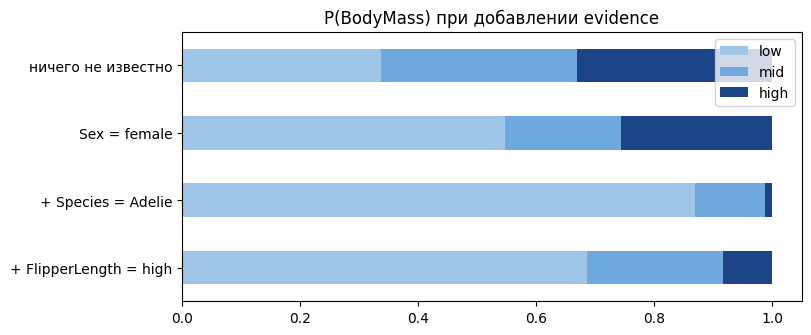

In [8]:
steps = [("ничего не известно", {}), ("Sex = female", {"Sex": "female"}),
         ("+ Species = Adelie", {"Sex": "female", "Species": "Adelie"}),
         ("+ FlipperLength = high", {"Sex": "female", "Species": "Adelie", "FlipperLength": "high"})]  
# последовательное добавление evidence, чтобы увидеть, как меняется распределение BodyMass

tab = pd.DataFrame({name: net.query("BodyMass", ev) for name, ev in steps}).T
display(tab.round(3))

tab.plot.barh(stacked=True, figsize=(8, 3.5), title="P(BodyMass) при добавлении evidence", color=["#9fc5e8", "#6fa8dc", "#1c4587"])
plt.gca().invert_yaxis()
plt.show()

Исследуемая переменная -  `BodyMass`.

1. **Ничего не известно:** распределение равномерно (≈ 1/3 на каждое состояние) -  терцили.
2. **`Sex = Female`:** вероятность `low` возрастает, а `high` падает: самки легче самцов (родитель `Sex` влияет на потомка напрямую).
3. **+ `Species = Adelie`:** вероятность `low` ещё выше, `high` ещё ниже: Adelie - один из мелких видов, и среди самок Adelie большинство лёгких (родитель `Species` -  второй источник информации об этом потомке).
4. **+ `FlipperLength = high`:** распределение смещается в сторону `mid` и `high`, вероятность `low` падает. Здесь evidence получен от потомка `BodyMass` (ребро `BodyMass → FlipperLength`): если у самки Adelie длинные ласты, вероятнее, что она крупнее обычной, поскольку при данном виде длина ласт растёт вместе с массой.

Итог: информация о причинах (`Sex`, `Species`) и о следствии (`FlipperLength`) сдвигает распределение в разные стороны, а величина сдвига определяется структурой графа: сеть учитывает, через какие рёбра информация передаётся. Если бы ребра `BodyMass → FlipperLength` не было, шаг 4 не изменил бы распределение `BodyMass` при известных `Sex` и `Species`.

# Анализ структуры

- Выбрать одно из рёбер построенной сети и удалить его
- Повторить один из вероятностных запросов и сравнить результаты до и после изменения структуры

In [9]:
net_cut = BN(df, {**parents, "FlipperLength": ["Species"]}) # удаляем ребро BodyMass → FlipperLength
emp = df[df["BodyMass"] == "high"]["FlipperLength"].value_counts(normalize=True).reindex(net.states["FlipperLength"])  
# эмпирическая P(FlipperLength | BodyMass=high) — для сравнения с обеими сетями

display(pd.DataFrame({"с ребром": net.query("FlipperLength", {"BodyMass": "high"}),
                      "без ребра": net_cut.query("FlipperLength", {"BodyMass": "high"}), "данные": emp}).T.round(3))
display(pd.DataFrame({"с ребром": net.query("BodyMass", {"Species": "Adelie", "Sex": "female", "FlipperLength": "high"}),
                      "без ребра": net_cut.query("BodyMass", {"Species": "Adelie", "Sex": "female", "FlipperLength": "high"})}).T.round(3))


net_rev = BN(df, {**parents, "Species": ["Island"], "Island": []})  # разворачиваем ребро Species → Island
display(pd.DataFrame({"Species -> Island": net.query("Species", {"Island": "Dream"}),
                      "Island -> Species": net_rev.query("Species", {"Island": "Dream"})}).T.round(3))
print("Макс. расхождение совместных распределений при развороте ребра:", float(np.abs(net.joint - net_rev.joint.transpose(
    [net_rev.nodes.index(v) for v in net.nodes])).max()))

,low,mid,high
с ребром,0.046,0.123,0.831
без ребра,0.066,0.153,0.781
данные,0.027,0.109,0.864


,low,mid,high
с ребром,0.686,0.230,0.083
без ребра,0.868,0.118,0.013


,Adelie,Chinstrap,Gentoo
Species -> Island,0.448,0.544,0.008
Island -> Species,0.444,0.548,0.008


Макс. расхождение совместных распределений при развороте ребра: 0.0007907810121863916


**Удаление ребра `BodyMass → FlipperLength`.** После удаления `FlipperLength` зависит только от вида. В первом запросе, `P(FlipperLength | BodyMass = high)`, результат изменился: в исходной сети масса тела напрямую повышает вероятность длинных ласт, а без ребра информация о массе влияет на ласты лишь опосредованно (тяжёлая масса → вероятнее крупный вид → длиннее ласты). Сравнение с данными показывает, какая из версий лучше описывает наблюдения: исходная сеть ближе к частотам в данных, потому что ребро несёт реальную информацию. Во втором запросе (масса самки Adelie при длинных ластах) без ребра evidence о ластах вообще перестаёт влиять на массу: распределение совпадает с `P(BodyMass | Species, Sex)`.

**Почему структура влияет на вывод.** Граф определяет, какие переменные считаются условно независимыми. Удаляя ребро, мы утверждаем, что `FlipperLength` не зависит от `BodyMass` при известном виде, и вероятностный вывод перестаёт передавать информацию по этому пути. Структура - это набор допущений о независимости, от которых прямо зависят результаты запросов.

**Насколько уверенно можно выбирать направление рёбер по данным.** Во втором эксперименте развернули ребро `Species → Island` (в `Island → Species`): ответ на запрос практически не изменился, а совместные распределения совпадают с точностью до сглаживания. Сети с развёрнутым ребром эквивалентны по Маркову: они описывают одно и то же распределение, и данные не позволяют различить такие направления. Данные позволяют обнаружить зависимость, но не её направление.

# Причинность

- Ответить на вопрос: можно ли считать построенную байесовскую сеть причинной моделью?
- Объяснить, на каком основании делается такое предположение

In [10]:
display(pd.DataFrame({"P(Sex)": net.query("Sex"), # априорное распределение пола
                      "P(Sex | BodyMass=high) -  наблюдение": net.query("Sex", {"BodyMass": "high"}),
                      "P(Sex | do(BodyMass=high)) -  вмешательство": net.query("Sex", do={"BodyMass": "high"})}).T.round(3))
display(pd.DataFrame({"P(BodyMass)": net.query("BodyMass"),
                      "P(BodyMass | FlipperLength=high) -  наблюдение": net.query("BodyMass", {"FlipperLength": "high"}),
                      "P(BodyMass | do(FlipperLength=high)) -  вмешательство": net.query("BodyMass", do={"FlipperLength": "high"})}).T.round(3))

,female,male
P(Sex),0.496,0.504
P(Sex | BodyMass=high) - наблюдение,0.385,0.615
P(Sex | do(BodyMass=high)) - вмешательство,0.496,0.504


,low,mid,high
P(BodyMass),0.337,0.332,0.331
P(BodyMass | FlipperLength=high) - наблюдение,0.022,0.149,0.828
P(BodyMass | do(FlipperLength=high)) - вмешательство,0.337,0.332,0.331


**Можно ли считать построенную сеть причинной моделью? В целом нет -  только отдельные связи при дополнительных допущениях.**

Байесовская сеть - способ записать совместное распределение как произведение условных вероятностей; стрелка означает «условное распределение потомка зависит от родителя», а не «родитель вызывает потомка». Ту же совместную вероятность можно записать разными графами и данные их не различают. Причинной сеть становится только если дополнительно принять, что стрелки отражают механизмы, а также, что нет скрытых общих причин и нет вмешательств, не отражённых в данных.

**Какие связи можно считать причинными.**
- `Sex → BodyMass`: пол определяется биологически, поэтому масса не может быть причиной пола (временной порядок); различие масс между полами - известный биологический диморфизм.
- `Species → BodyMass`, `Species → FlipperLength`, `Species → BillLength/BillDepth`: вид задаётся генетически и предшествует размерам тела; обратное направление невозможно.
- `Sex → BillLength/BillDepth`: то же основание, что и для массы.

**Какие связи причинными считать нельзя.**
- `BodyMass → FlipperLength`: оба признака - проявления общей причины («размер организма»: возраст, питание, развитие), которая не записана в данных; стрелка отражает ассоциацию, а не механизм «масса удлиняет ласты».
- `Species → Island`: это скорее география распределения колоний, чем причинное влияние; остров мог быть выбран и другими факторами, а направление не определимо по данным.
- Данные наблюдательные, нет возраста и года, поэтому возможны скрытые общие причины и смещение отбора.

**Наблюдение и вмешательство.** Условная вероятность `P(Sex | BodyMass = high)` отличается от априорной, потому что тяжёлая масса - свидетельство в пользу самца, но `P(Sex | do(BodyMass = high))` совпадает с априорной: если искусственно сделать пингвина тяжёлым (например, откормить), пол не изменится. Это согласуется с реальностью, так как в графе `Sex` - причина `BodyMass`, а не следствие. Аналогично `do(FlipperLength = high)` не меняет распределение массы (ласты - следствие в графе), хотя при наблюдении длинных ласт вывод о массе меняется. Если принять противоположное направление ребра, вывод был бы другим, и данные не могут решить, какой вариант верен. Поэтому вмешательства имеют смысл только для связей, направление которых обосновано предметными знаниями.

# Итог

Кратко сформулировать:
- что удалось узнать с помощью сети
- какие зависимости оказались наиболее интересными
- как evidence влияет на вероятности
- насколько результаты зависят от выбранной структуры
- какие ограничения имеет построенная модель

**Что удалось узнать с помощью сети.** Сеть из 7 вершин и 9 рёбер на данных Palmer Penguins воспроизводит основные закономерности: вид определяет остров и размеры, пол влияет на массу и размеры клюва, масса связана с длиной ласт. С её помощью можно считать вероятности как «от причин к следствиям» (масса при известном виде и поле), так и «от следствий к причинам» (вид по острову и размерам).

**Какие зависимости оказались наиболее интересными.**
- Парадокс Симпсона: общая отрицательная корреляция длины и глубины клюва исчезает (становится положительной) внутри видов, поэтому ребро по одной корреляции было бы ошибочным.
- Эффект объяснения: тяжёлая масса указывает на самца, но знание вида (Gentoo) это свидетельство ослабляет. 
- Остров почти однозначно определяет вид для Torgersen и исключает Gentoo для Dream.

**Как evidence влияет на вероятности.** Информация о родителях и о потомках меняет распределение интересующей переменной в разные стороны; величина сдвига определяется путями в графе. Последовательное добавление evidence сужает распределение, но не всегда монотонно: новое свидетельство может частично отменять предыдущее (как `FlipperLength = high` при известных поле и виде).

**Зависимость от структуры.** Удаление ребра `BodyMass → FlipperLength` изменило ответы на запросы; разворот ребра `Species → Island` не изменил ничего (марковски эквивалентные сети). Значит, результаты зависят от того, какие допущения о независимости заложены в граф, а направление части рёбер данные определить не могут.

**Ограничения модели.** Дискретизация в 3 интервала теряет информацию и зависит от выбранных границ; выборка небольшая (333 наблюдения), редкие конфигурации оцениваются по сглаживанию; граф предполагает условную независимость, которая в данных нарушается (длина и глубина клюва внутри вида связаны); данные наблюдательные, нет возраста и года, поэтому нельзя рассматривать сеть как причинную модель целиком; нет проверки качества на отложенных данных, это вероятностное описание, а не обученный предсказатель.